# z025 - Exploración: ¿quiénes se van?

**Idea:** antes de crear variables nuevas, mirar si los que se van (BAJA+2) son distintos en edad, antigüedad,
límite de tarjeta, saldos y sueldo. Para cada variable se arman **rangos** y se calcula el **% de BAJA+2** en cada uno.

Cómo leer las tablas:
- `pct_baja2`: % de clientes del rango que son BAJA+2.
- `veces_promedio`: cuántas veces el promedio general. **2 = se van el doble que el promedio**; 0,5 = la mitad.

Meses 202103 a 202106 (los que tienen BAJA+2). Tarda 1-2 minutos.

In [1]:
# --- 1. Librerías y datos ---
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import mannwhitneyu

columnas = ["numero_de_cliente", "foto_mes", "clase_ternaria", "cliente_edad", "cliente_antiguedad",
            "tcuentas", "mcuentas_saldo", "mpayroll", "mpayroll2", "cpayroll_trx", "cpayroll2_trx",
            "mtransferencias_recibidas", "ctransferencias_recibidas",
            "chomebanking_transacciones", "cmobile_app_trx",
            "mplazo_fijo_pesos", "mplazo_fijo_dolares", "minversion1_pesos", "minversion1_dolares", "minversion2",
            "Visa_mlimitecompra", "Master_mlimitecompra", "Visa_msaldototal", "Master_msaldototal",
            "Visa_mconsumototal", "Master_mconsumototal"]
df = pd.read_parquet("../competencia_01.parquet", columns=columnas)
df = df[df["foto_mes"].between(202103, 202106)].copy()
df["baja2"] = (df["clase_ternaria"] == "BAJA+2").astype(int)

PROMEDIO = df["baja2"].mean() * 100
print(f"{len(df):,} filas | % BAJA+2 promedio: {PROMEDIO:.2f}%")

654,066 filas | % BAJA+2 promedio: 0.62%


In [2]:
# --- 2. Variables que vamos a mirar (las de la hoja "Nuevas variables") ---
def div(a, b):
    # División que devuelve NaN si el denominador es 0 o negativo
    return a / b.where(b > 0)

suma = lambda cols: df[cols].fillna(0).sum(axis=1)   # suma tratando NaN como 0

df["m_limite_total"]     = suma(["Visa_mlimitecompra", "Master_mlimitecompra"])
df["m_saldo_tarjetas"]   = suma(["Visa_msaldototal", "Master_msaldototal"])
df["m_tarjetas_consumo"] = suma(["Visa_mconsumototal", "Master_mconsumototal"])
df["r_saldo_limite"]     = div(df["m_saldo_tarjetas"], df["m_limite_total"])
df["r_consumo_limite"]   = div(df["m_tarjetas_consumo"], df["m_limite_total"])
df["m_inversiones_total"] = suma(["mplazo_fijo_pesos", "mplazo_fijo_dolares", "minversion1_pesos",
                                  "minversion1_dolares", "minversion2"])
df["m_patrimonio_banco"] = df["mcuentas_saldo"].fillna(0) + df["m_inversiones_total"]
df["m_payroll_total"]    = suma(["mpayroll", "mpayroll2"])

In [3]:
# --- 3. Funciones ---
def tabla_rangos(grupo, nombre):
    """% de BAJA+2 en cada rango. 'grupo' es una Serie con el rango de cada fila."""
    t = df.groupby(grupo, observed=True)["baja2"].agg(clientes="size", baja2="sum")
    t["pct_baja2"] = (t["baja2"] / t["clientes"] * 100).round(2)
    t["veces_promedio"] = (t["pct_baja2"] / PROMEDIO).round(2)
    t.index.name = nombre
    return t

def rangos_por_mes(col, n=5):
    """Rangos (quintiles) calculados DENTRO de cada mes: así la inflación no mezcla meses.
    Solo con valores > 0 (los ceros y negativos se etiquetan aparte)."""
    pct = df[col].where(df[col] > 0).groupby(df["foto_mes"]).rank(pct=True)
    return pd.cut(pct, np.linspace(0, 1, n + 1), labels=[f"Q{i} " + ("(más bajo)" if i == 1 else "(más alto)" if i == n else "")
                                                          for i in range(1, n + 1)], include_lowest=True)

def grafico(t, titulo):
    ax = t["veces_promedio"].plot(kind="bar", figsize=(8, 3), color="#305496")
    ax.axhline(1, color="red", linestyle="--", linewidth=1)   # línea = promedio
    ax.set_title(titulo); ax.set_ylabel("veces el promedio"); ax.set_xlabel("")
    plt.xticks(rotation=30, ha="right"); plt.tight_layout(); plt.show()

def comparar(col):
    """Mediana BAJA+2 vs CONTINUA + prueba de Mann-Whitney."""
    a = df.loc[df["clase_ternaria"] == "BAJA+2", col].dropna()
    b = df.loc[df["clase_ternaria"] == "CONTINUA", col].dropna()
    p = mannwhitneyu(a, b).pvalue
    print(f"{col}: mediana BAJA+2 = {a.median():,.1f} | CONTINUA = {b.median():,.1f} | p-valor = {p:.1e}")

## 4. Edad y antigüedad
**Ojo con el p-valor:** con tantos clientes casi cualquier diferencia da p muy chico (significativa).
Lo que importa es **cuánto** cambia el % de bajas entre rangos (columna `veces_promedio`).

cliente_edad: mediana BAJA+2 = 46.0 | CONTINUA = 45.0 | p-valor = 5.8e-03


,clientes,baja2,pct_baja2,veces_promedio
edad (10 grupos),,,,
"(17.0, 31.0]",71301,492,0.69,1.11
"(31.0, 35.0]",65486,425,0.65,1.05
"(35.0, 39.0]",76670,443,0.58,0.93
"(39.0, 42.0]",61643,352,0.57,0.92
"(42.0, 45.0]",59208,317,0.54,0.87
"(45.0, 49.0]",69782,374,0.54,0.87
"(49.0, 53.0]",58174,299,0.51,0.82
"(53.0, 59.0]",71944,418,0.58,0.93
"(59.0, 65.0]",55302,412,0.75,1.21


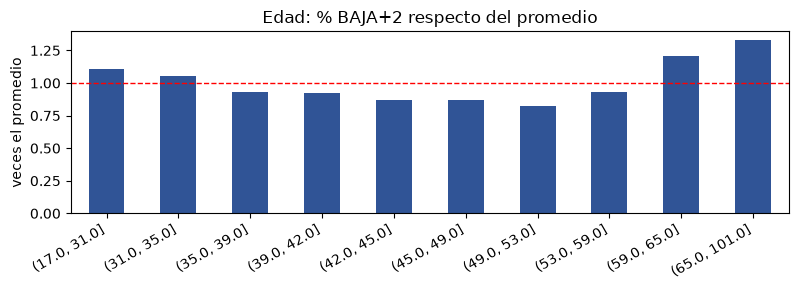

In [4]:
comparar("cliente_edad")
t = tabla_rangos(pd.qcut(df["cliente_edad"], 10, precision=0), "edad (10 grupos)")
display(t); grafico(t, "Edad: % BAJA+2 respecto del promedio")

cliente_antiguedad: mediana BAJA+2 = 86.0 | CONTINUA = 127.0 | p-valor = 1.3e-81


,clientes,baja2,pct_baja2,veces_promedio
antigüedad (meses),,,,
0-6,7834,47,0.60,0.96
7-12,13560,119,0.88,1.42
13-24,34219,340,0.99,1.59
25-60,102647,938,0.91,1.46
61-120,152092,1040,0.68,1.09
121-240,260242,1227,0.47,0.76
> 240,83472,356,0.43,0.69


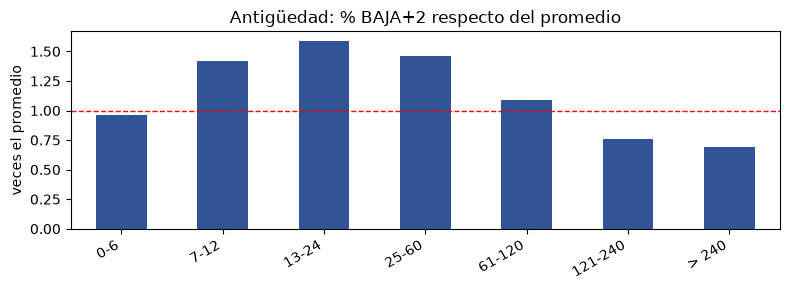

In [5]:
comparar("cliente_antiguedad")
cortes = [-1, 6, 12, 24, 60, 120, 240, 1000]   # meses
t = tabla_rangos(pd.cut(df["cliente_antiguedad"], cortes,
                        labels=["0-6", "7-12", "13-24", "25-60", "61-120", "121-240", "> 240"]), "antigüedad (meses)")
display(t); grafico(t, "Antigüedad: % BAJA+2 respecto del promedio")

## 5. Límite de tarjetas (rangos)

,clientes,baja2,pct_baja2,veces_promedio
límite total,,,,
Q1 (más bajo),130413,961,0.74,1.19
Q2,119549,701,0.59,0.95
Q3,127896,605,0.47,0.76
Q4,124362,536,0.43,0.69
Q5 (más alto),125277,425,0.34,0.55
sin tarjeta / límite 0,26569,839,3.16,5.08


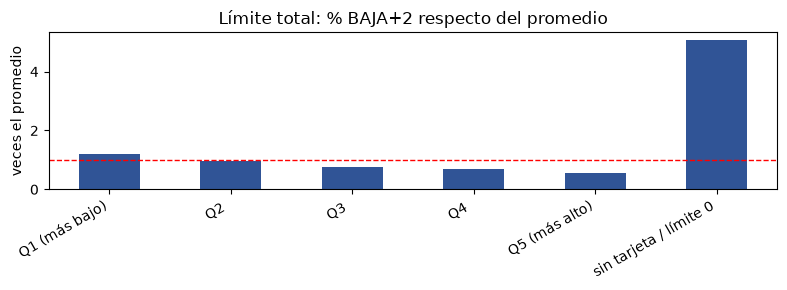

In [6]:
rango_limite = rangos_por_mes("m_limite_total").astype(str)
rango_limite[df["m_limite_total"] <= 0] = "sin tarjeta / límite 0"
df["rango_limite"] = rango_limite
t = tabla_rangos(df["rango_limite"], "límite total")
display(t); grafico(t, "Límite total: % BAJA+2 respecto del promedio")

## 6. Saldo sobre límite y consumo sobre límite, DENTRO de cada rango de límite
Pregunta: ¿"usar poco el límite" significa lo mismo para alguien con límite alto que con límite bajo?
Si en todos los rangos los BAJA+2 tienen medianas más bajas, el cociente sirve parejo para todos.

In [7]:
con_tarjeta = df[df["rango_limite"] != "sin tarjeta / límite 0"]
for col in ["r_saldo_limite", "r_consumo_limite"]:
    t = (con_tarjeta[con_tarjeta["clase_ternaria"].isin(["BAJA+2", "CONTINUA"])]
         .pivot_table(index="rango_limite", columns="clase_ternaria", values=col, aggfunc="median").round(3))
    print(col, "(mediana)"); display(t)

r_saldo_limite (mediana)


clase_ternaria,BAJA+2,CONTINUA
rango_limite,,
Q1 (más bajo),0.006,0.112
Q2,0.010,0.084
Q3,0.010,0.059
Q4,0.009,0.043
Q5 (más alto),0.004,0.026


r_consumo_limite (mediana)


clase_ternaria,BAJA+2,CONTINUA
rango_limite,,
Q1 (más bajo),0.000,0.035
Q2,0.001,0.031
Q3,0.002,0.022
Q4,0.002,0.019
Q5 (más alto),0.002,0.014


## 7. Saldos y plata en el banco

mcuentas_saldo: mediana BAJA+2 = -1,116.5 | CONTINUA = 37,916.5 | p-valor = 0.0e+00


,clientes,baja2,pct_baja2,veces_promedio
mcuentas_saldo,,,,
Q1 (más bajo),104356,879,0.84,1.35
Q2,104358,404,0.39,0.63
Q3,104359,219,0.21,0.34
Q4,104358,144,0.14,0.23
Q5 (más alto),104360,106,0.10,0.16
cero,4038,77,1.91,3.07
negativo,128237,2238,1.75,2.81


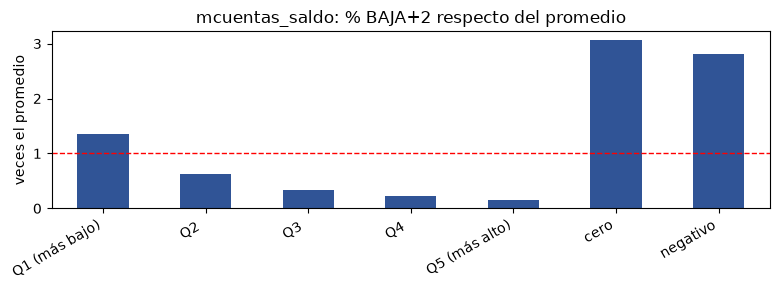

m_patrimonio_banco: mediana BAJA+2 = -935.3 | CONTINUA = 49,774.6 | p-valor = 0.0e+00


,clientes,baja2,pct_baja2,veces_promedio
m_patrimonio_banco,,,,
Q1 (más bajo),105365,892,0.85,1.37
Q2,105366,377,0.36,0.58
Q3,105365,213,0.20,0.32
Q4,105366,170,0.16,0.26
Q5 (más alto),105369,131,0.12,0.19
cero,3892,77,1.98,3.18
negativo,123343,2207,1.79,2.88


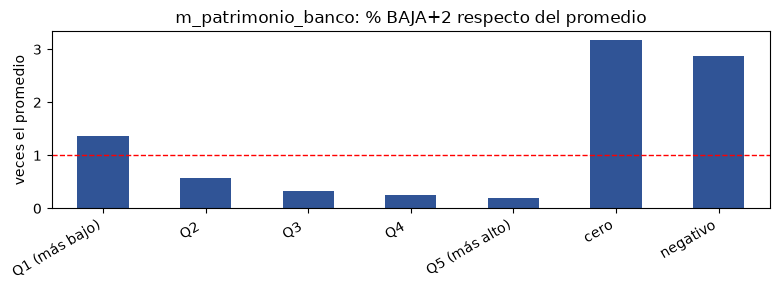

In [8]:
for col in ["mcuentas_saldo", "m_patrimonio_banco"]:
    comparar(col)
    rango = rangos_por_mes(col).astype(str)
    rango[df[col] == 0] = "cero"
    rango[df[col] < 0] = "negativo"
    t = tabla_rangos(rango, col)
    display(t); grafico(t, f"{col}: % BAJA+2 respecto del promedio")

## 8. Sueldo

,clientes,baja2,pct_baja2,veces_promedio
sueldo,,,,
con sueldo,353251,315,0.09,0.14
sin sueldo,300815,3752,1.25,2.01


,clientes,baja2,pct_baja2,veces_promedio
monto de sueldo,,,,
Q1 (más bajo),70576,153,0.22,0.35
Q2,70722,47,0.07,0.11
Q3,70651,46,0.07,0.11
Q4,70650,29,0.04,0.06
Q5 (más alto),70652,40,0.06,0.10
sin sueldo,300815,3752,1.25,2.01


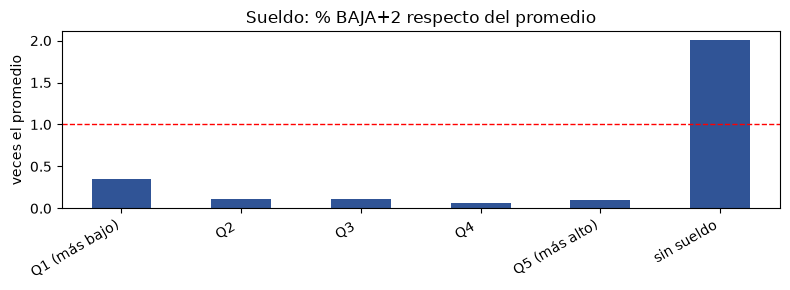

In [9]:
df["tiene_payroll"] = np.where(df["m_payroll_total"] > 0, "con sueldo", "sin sueldo")
display(tabla_rangos(df["tiene_payroll"], "sueldo"))

con_sueldo = df["m_payroll_total"] > 0
rango = rangos_por_mes("m_payroll_total").astype(str)
rango[~con_sueldo] = "sin sueldo"
t = tabla_rangos(rango, "monto de sueldo")
display(t); grafico(t, "Sueldo: % BAJA+2 respecto del promedio")

## 9. Cantidad de cuentas (tcuentas)

In [10]:
display(tabla_rangos(df["tcuentas"], "tcuentas"))

,clientes,baja2,pct_baja2,veces_promedio
tcuentas,,,,
1,650797,4012,0.62,1.0
2,3269,55,1.68,2.7


## 10. Chequeos de datos
**a)** ¿Las transferencias recibidas incluyen el sueldo? Si las incluyeran, en los clientes con sueldo
las transferencias deberían ser casi siempre ≥ sueldo.
**b)** ¿La app está sumada dentro de home banking? Si hay muchos clientes con app > 0 y home banking = 0, no está sumada.

In [11]:
# a) Transferencias vs sueldo (solo clientes con sueldo)
cs = df[df["m_payroll_total"] > 0]
print(f"Clientes con sueldo: {len(cs):,}")
print(f"  con transferencias recibidas = 0:          {(cs['mtransferencias_recibidas'].fillna(0) == 0).mean():.1%}")
print(f"  con transferencias recibidas >= sueldo:    {(cs['mtransferencias_recibidas'] >= cs['m_payroll_total']).mean():.1%}")
print(f"  mediana transferencias / sueldo:           {(cs['mtransferencias_recibidas'] / cs['m_payroll_total']).median():.2f}")

# b) App vs home banking
app = df["cmobile_app_trx"].fillna(0) > 0
hb  = df["chomebanking_transacciones"].fillna(0) > 0
print(f"\nApp > 0 y home banking = 0: {(app & ~hb).sum():,} filas ({(app & ~hb).mean():.1%})")
print(f"App > 0 y app > home banking: {(app & (df['cmobile_app_trx'] > df['chomebanking_transacciones'])).sum():,} filas")
print("Correlación app vs home banking:", round(df["cmobile_app_trx"].corr(df["chomebanking_transacciones"]), 2))

Clientes con sueldo: 353,251
  con transferencias recibidas = 0:          21.1%
  con transferencias recibidas >= sueldo:    37.5%
  mediana transferencias / sueldo:           0.63

App > 0 y home banking = 0: 65,085 filas (10.0%)
App > 0 y app > home banking: 65,085 filas
Correlación app vs home banking: -0.05


## Conclusiones
(202103-202106, 654.066 filas, promedio 0,62% BAJA+2; se mira `veces_promedio`, no el p-valor)
- **Edad:** forma de U, efecto moderado: 65+ = 1,33× y 59-65 = 1,21×; 17-31 = 1,11×; el medio (42-53) ≈ 0,85×.
- **Antigüedad:** la más clara de las dos: 13-24 meses = 1,59× y 7-60 meses ≈ 1,4-1,6×; más de 10 años ≈ 0,7×. Los muy nuevos (0-6) están en el promedio.
- **Límite (rangos):** separa por sí solo: baja parejo de Q1 1,19× a Q5 0,55×. Lo fuerte es **sin tarjeta / límite 0: 3,16% = 5,1×**.
- **Saldo/límite dentro de cada rango:** en **todos** los rangos los BAJA+2 tienen mediana ≈ 0 (0,004-0,010 saldo; 0-0,002 consumo) vs CONTINUA 0,03-0,11 → el cociente sirve parejo. La diferencia es más grande en límites bajos.
- **Saldos y patrimonio:** saldo negativo 2,8× y cero 3,1×; Q1 1,35×; Q5 0,16×. m_patrimonio_banco da casi igual que mcuentas_saldo (las inversiones agregan poco).
- **Sueldo:** la señal más fuerte: sin sueldo 1,25% (2,0×) vs con sueldo 0,09% (0,14×). Entre los que cobran, solo Q1 (sueldo bajo) se va algo más (0,35×).
- **tcuentas:** 2 cuentas = 2,7×, pero son solo 3.269 clientes (0,5%): poco peso.
- **Chequeos:** las transferencias recibidas **no** incluyen el sueldo (21% de los que cobran tienen 0 transferencias; mediana transf/sueldo 0,63) → m_ingresos_total puede sumar los dos. **App:** `cmobile_app_trx` vale solo 0/1 (marca de "usa la app", no cantidad; chequeo aparte) → no se suma en c_trx_digitales (queda home banking + call center).
